# 04 · Fractal stencils: Newman–Moore, the trinomial, and `haah_z`

Notebook 03 ended with a stencil that factors direction by direction and a degeneracy that ignores the
system size. This notebook breaks the factorisation. Three classical stencils:

| name | $f$ | as a cellular automaton |
|---|---|---|
| Newman–Moore | $1+x+y$ | $t_{r+1}=(1+x)\,t_r$ |
| trinomial | $1+x+x^2+y$ | $t_{r+1}=(1+x+x^2)\,t_r$ |
| `haah_z` | $1+x+x^2+y+xy+y^2$ | $t_{r+2}=(1+x+x^2)\,t_r+(1+x)\,t_{r+1}$ |

and the Hamiltonian $H=-\sum_r\prod_{s\in f}\sigma_{r+s}$ for each. One convention throughout: $F$ has a
row per term and a column per spin, flipping the spins in $u$ violates the terms $Fu$, the ground
states and flip symmetries are $\ker F$ (the same set, starting from all spins up), and the relations
among terms are $\ker F^{\mathsf T}$.

Text(0.5, 1.05, 'dark outline = the origin; x to the right, y up')

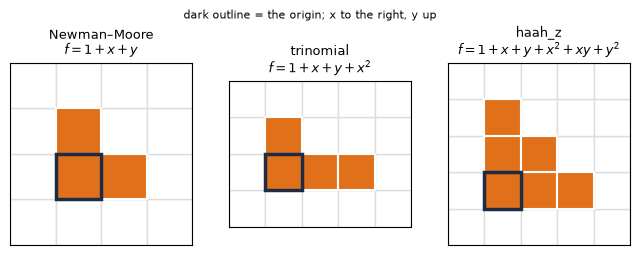

In [1]:
import sys
sys.path.insert(0, "..")

from math import log2, sqrt
import numpy as np
import matplotlib.pyplot as plt
import gsd
from gsd import Poly, closed_form, fractals

NM = gsd.NEWMAN_MOORE
TRI = gsd.classical("trinomial", gsd.STENCILS["trinomial"])
HZ = gsd.classical("haah_z", gsd.STENCILS["haah_z"])
DW = gsd.classical("domain_wall", "1 + x")          # control: an ordinary, mobile domain wall
GREENS = "Greens"


def draw_stencil(ax, f, title):
    pts = np.array([e for e, _ in f.offsets()])
    lo, hi = pts.min(0) - 1, pts.max(0) + 1
    for i in range(lo[0], hi[0] + 1):
        for j in range(lo[1], hi[1] + 1):
            ax.add_patch(plt.Rectangle((i - .5, j - .5), 1, 1, fc="white", ec="#dddddd"))
    for i, j in pts:
        ax.add_patch(plt.Rectangle((i - .5, j - .5), 1, 1, fc="#e0701a", ec="white", lw=1.5))
    ax.add_patch(plt.Rectangle((-.5, -.5), 1, 1, fc="none", ec="#1f2a44", lw=2.5))
    ax.set_xlim(lo[0] - .5, hi[0] + .5), ax.set_ylim(lo[1] - .5, hi[1] + .5)
    ax.set_aspect("equal"), ax.set_xticks([]), ax.set_yticks([])
    ax.set_title(title, fontsize=9)


fig, ax = plt.subplots(1, 3, figsize=(8, 2.6))
for a, (m, name) in zip(ax, [(NM, "Newman–Moore"), (TRI, "trinomial"), (HZ, "haah_z")]):
    draw_stencil(a, m.generators[0].z[0], f"{name}\n$f = {m.generators[0].z[0]}$")
fig.suptitle("dark outline = the origin; x to the right, y up", fontsize=8, y=1.05)

## 1. A degeneracy that depends on arithmetic

All three grow with $L$ — linearly, so *sub-extensive* (extensive would be $\propto L^2$) — but only at
special sizes. One extra row can destroy almost all of it. That is **UV/IR mixing**: a microscopic
detail (is $L$ a power of 2? is it divisible by 3?) controls a macroscopic observable, which no smooth
field theory can reproduce. The toric code's flat 4 is the opposite extreme.

In [2]:
print("   L   Newman-Moore  trinomial  haah_z")
for L in (15, 16, 17, 31, 32, 33, 63, 64, 65):
    print(f"{L:4d}  {NM.log_gsd(L):12d}  {TRI.log_gsd(L):9d}  {HZ.log_gsd(L):6d}")
print("\nhaah_z: N_c(256,256) =", closed_form.haah_z(256, 256), "  N_c(256,255) =", closed_form.haah_z(256, 255))

   L   Newman-Moore  trinomial  haah_z
  15            14         13      27
  16             0         16      31
  17             0          1       1
  31            30         31       1
  32             0         32      63
  33             2          1       3
  63            62         61     123


  64             0         64     127
  65             0          1       1

haah_z: N_c(256,256) = 511   N_c(256,255) = 2


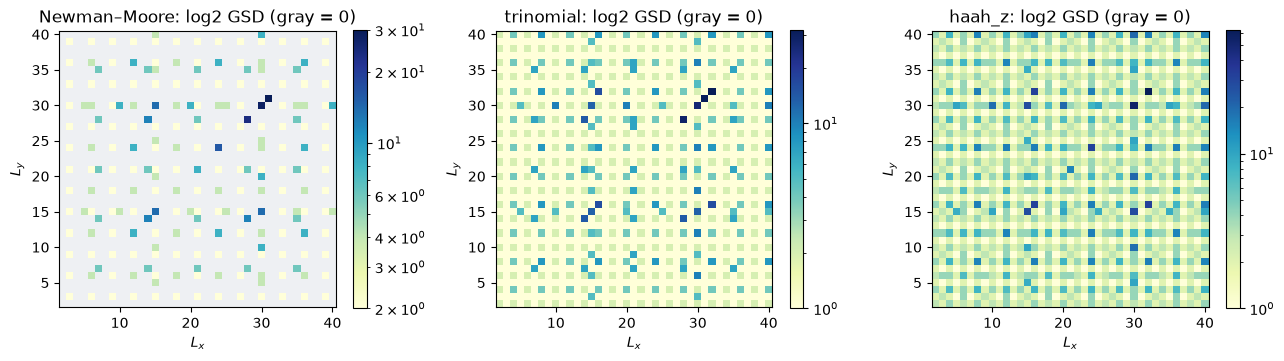

In [3]:
LS = list(range(2, 41))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (m, name) in zip(axes, [(NM, "Newman–Moore"), (TRI, "trinomial"), (HZ, "haah_z")]):
    g = np.array([[m.log_gsd((lx, ly)) for lx in LS] for ly in LS], dtype=float)
    im = ax.imshow(np.where(g > 0, g, np.nan), origin="lower", cmap="YlGnBu", norm="log",
                   extent=[1.5, LS[-1] + .5, 1.5, LS[-1] + .5])
    ax.set_facecolor("#eef0f3")
    ax.set_title(f"{name}: log2 GSD (gray = 0)"), ax.set_xlabel("$L_x$"), ax.set_ylabel("$L_y$")
    fig.colorbar(im, ax=ax, shrink=.8)
plt.tight_layout()

The trinomial grid is **asymmetric**: $f$ has degree 2 in $x$ and 1 in $y$, so
$N_c(L_x,L_y)\neq N_c(L_y,L_x)$ in general, and the bound is $N_c\le L_x$ rather than $\min(L_x,L_y)$.

In [4]:
print("trinomial (15,3) vs (3,15):", TRI.log_gsd((15, 3)), TRI.log_gsd((3, 15)))
grid = {(lx, ly): TRI.log_gsd((lx, ly)) for lx in LS for ly in LS}
print("N_c <= Lx everywhere:", all(v <= lx for (lx, ly), v in grid.items()),
      "   N_c <= min(Lx, Ly) everywhere:", all(v <= min(k) for k, v in grid.items()))

trinomial (15,3) vs (3,15): 5 1


N_c <= Lx everywhere: True    N_c <= min(Lx, Ly) everywhere: False


## 2. Closed forms

### Newman–Moore family: one gcd

Both Newman–Moore and the trinomial are $f=y+g(x)$. Notebook 02 showed what that buys: modulo $f$,
$y=g(x)$, so $R/(f)\cong\mathbb F_2[x]/(x^{L_x}-1,\ g(x)^{L_y}-1)$ and

$$\log_2\mathrm{GSD}=\deg\gcd\big(x^{L_x}+1,\ g(x)^{L_y}+1\big).$$

One polynomial gcd replaces an $O((L_xL_y)^3)$ elimination. (Splitting $L=2^a m$ with $m$ odd gives the
equivalent $\min(2^a,2^b)\cdot\deg\gcd(x^{m_x}+1,\ g^{m_y}+1)$; note the exponent on $g$ is $m_y$ —
swapping it for $m_x$ is invisible on square tori and wrong on 83 of the 529 rectangles with sides
2..24.)

In [5]:
ok = sum(closed_form.newman_moore_family(lx, ly, (0, 1, 2)) == TRI.log_gsd((lx, ly), method="brute")
         for lx in range(2, 25) for ly in range(2, 25))
print(f"trinomial gcd formula vs brute force: {ok}/529")
print("sizes brute force cannot touch:",
      {L: closed_form.newman_moore_family(L, L, (0, 1, 2)) for L in (85, 91, 127, 255, 1023, 4095)})

trinomial gcd formula vs brute force: 529/529
sizes brute force cannot touch: {85: 17, 91: 7, 127: 127, 255: 253, 1023: 1021, 4095: 4093}


**The trinomial's arithmetic.** On odd tori the count is the number of $\zeta\in\mu_{m_x}$ (the
$m_x$-th roots of unity in some $\mathbb F_{2^k}$) with $g(\zeta)\in\mu_{m_y}$. Since
$g=1+x+x^2=\Phi_3(x)$, its roots are exactly $\omega,\omega^2$: when $3\mid m$ those two roots lie in
$\mu_m$ but give $g=0\notin\mu_m$, so **divisibility by 3 removes two points** — the opposite of
`haah_z`, where it adds them. The maximal family is $m=2^k-1$, where $\mu_m=\mathbb F_{2^k}^\times$ is
everything, so $N(m,m)=m-2[k\text{ even}]$.

In [6]:
for k in range(2, 12):
    m = 2 ** k - 1
    print(f"m = 2^{k:<2d}- 1 = {m:5d}:  N = {closed_form.newman_moore_family(m, m, (0, 1, 2)):5d}"
          f"   predicted {m - 2 * (k % 2 == 0):5d}")

m = 2^2 - 1 =     3:  N =     1   predicted     1
m = 2^3 - 1 =     7:  N =     7   predicted     7
m = 2^4 - 1 =    15:  N =    13   predicted    13
m = 2^5 - 1 =    31:  N =    31   predicted    31
m = 2^6 - 1 =    63:  N =    61   predicted    61
m = 2^7 - 1 =   127:  N =   127   predicted   127
m = 2^8 - 1 =   255:  N =   253   predicted   253
m = 2^9 - 1 =   511:  N =   511   predicted   511
m = 2^10- 1 =  1023:  N =  1021   predicted  1021
m = 2^11- 1 =  2047:  N =  2047   predicted  2047


### `haah_z`: two straight lines over $\mathbb F_4$

`haah_z` is quadratic in $y$, so $y$ cannot be eliminated over $\mathbb F_2$. Over $\mathbb F_4=\{0,1,\omega,\omega^2\}$
it factors, $f=(x+\omega y+\omega^2)(x+\omega^2y+\omega)$: the "fractal" stencil is a pair of conjugate
lines meeting at the singular point $(1,1)$. Counting their points on the torus gives

$$N_c=2\min(2^a,2^b)\,N(m_x,m_y)-[a=b],\qquad N=\deg\gcd_{\mathbb F_4[y]}\big(y^{m_y}+1,\ (\omega y+\omega^2)^{m_x}+1\big).$$

The README has the derivation; here is the check.

In [7]:
print("(x + w y + w^2)(x + w^2 y + w) over F_4 has F_2 coefficients:",
      "x^2 + y^2 + 1 + xy + x + y  (w + w^2 = 1, w^3 = 1)")
ok = sum(closed_form.haah_z(lx, ly) == HZ.log_gsd((lx, ly), method="brute")
         for lx in range(2, 25) for ly in range(2, 25))
print(f"haah_z closed form vs brute force: {ok}/529")
print("first odd m coprime to 3 with N(m, m) > 1:", [m for m in range(5, 100, 2)
      if m % 3 and closed_form.curve_points(m, m) > 1])

(x + w y + w^2)(x + w^2 y + w) over F_4 has F_2 coefficients: x^2 + y^2 + 1 + xy + x + y  (w + w^2 = 1, w^3 = 1)


haah_z closed form vs brute force: 529/529
first odd m coprime to 3 with N(m, m) > 1: [85, 91]


## 3. The symmetries are fractals

Each kernel vector is a set of spins whose flip leaves every term invariant. Drawn on the torus they
are nested triangles. The reason: solving $f\cdot t=0$ for the top row turns the stencil into a linear
cellular automaton, and **the closed orbits of that automaton on the torus are the kernel vectors**.
From a single seed the automaton draws its light cone: Pascal's triangle mod 2 for Newman–Moore.

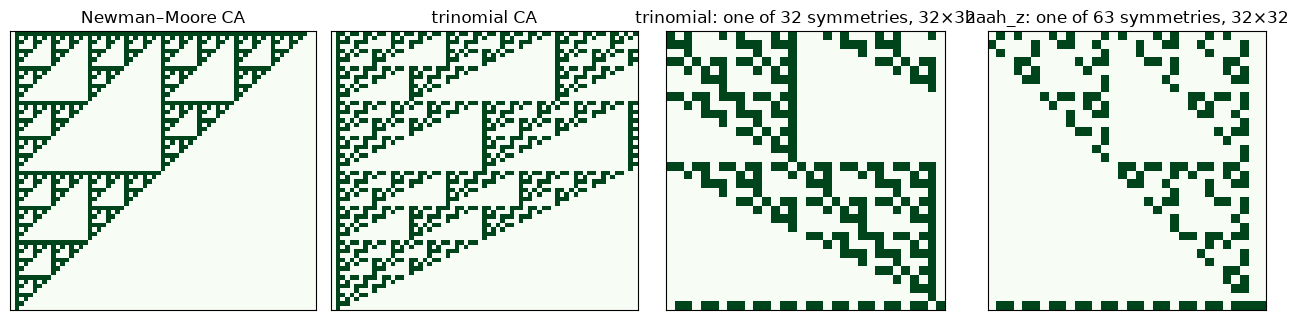

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for a, (exps, t) in zip(axes[:2], [((0, 1), "Newman–Moore CA"), ((0, 1, 2), "trinomial CA")]):
    a.imshow(fractals.ca_rows(exps, 64)[:, 64:], cmap=GREENS, origin="lower", aspect="auto")
    a.set_title(t), a.set_xticks([]), a.set_yticks([])
for a, (m, L) in zip(axes[2:], [(TRI, 32), (HZ, 32)]):
    S = m.symmetries(L)
    a.imshow(S[int(np.argmin(S.sum(1)))].reshape(L, L).T, cmap=GREENS, origin="lower")
    a.set_title(f"{m.name}: one of {len(S)} symmetries, {L}×{L}"), a.set_xticks([]), a.set_yticks([])
plt.tight_layout()

Any $GF(2)$ sum of symmetries is a symmetry; they form a group of $2^{N_c}$ elements, acting simply
transitively on the ground states.

In [9]:
L = 16
S = TRI.symmetries(L)
F = TRI.check_matrix(L)[:, L * L:]
combo = (np.random.default_rng(0).integers(0, 2, len(S)) @ S) % 2
print(f"{len(S)} generators on the {L}x{L} torus; a random combination is a symmetry:", not (F @ combo % 2).any())
print("relations (ker F^T) have the same dimension:", len(TRI.relations(L)))

16 generators on the 16x16 torus; a random combination is a symmetry: True
relations (ker F^T) have the same dimension: 16


## 4. Frobenius: why the fractal closes, and what happens when it does not

Over $\mathbb F_2$, $(a+b)^2=a^2+b^2$, so $f^{2^n}=f(x^{2^n},y^{2^n})$: **a power of a stencil is the
stencil blown up by $2^n$**. Flipping the spins on $u=\bar f^{\,2^n-1}$ (the reflected stencil, raised
to $2^n-1$) violates only the terms $\bar f\cdot u=\bar f^{\,2^n}$: three of them, at the corners of a
Sierpiński triangle of $3^n$ spins.

* On an $L\times L$ torus with $L=2^n-1$, $x^{2^n}=x$, so $\bar f^{\,2^n}=\bar f$ and $u+1$ is a closed
  symmetry: that is why $L=2^n-1$ is where Newman–Moore's degeneracy peaks at $L-1$.
* On an open plane the triangle cannot close: its three corners are isolated excitations that no local
  operator can move apart. Those are **fractons**.

In [10]:
fbar = Poly("1 + x^-1 + y^-1")
for n in range(1, 7):
    u, corners = fractals.power_pattern(fbar, n)
    print(f"n={n}: {len(u):4d} = 3^{n} flipped spins, violated terms {sorted(corners.terms)}")

n=1:    3 = 3^1 flipped spins, violated terms [(-2, 0), (0, -2), (0, 0)]
n=2:    9 = 3^2 flipped spins, violated terms [(-4, 0), (0, -4), (0, 0)]
n=3:   27 = 3^3 flipped spins, violated terms [(-8, 0), (0, -8), (0, 0)]
n=4:   81 = 3^4 flipped spins, violated terms [(-16, 0), (0, -16), (0, 0)]
n=5:  243 = 3^5 flipped spins, violated terms [(-32, 0), (0, -32), (0, 0)]
n=6:  729 = 3^6 flipped spins, violated terms [(-64, 0), (0, -64), (0, 0)]


## 5. The fractal dimension, exactly

For Newman–Moore, row $r$ of the automaton has $2^{\mathrm{popcount}(r)}$ cells, the first $2^n$ rows hold
$3^n$, and the box-counting dimension is $\log_2 3\approx1.585$. Naively the trinomial ($T=3$ terms)
would give $\log_2(1+T)=2$: space-filling. It does not, because terms collide.

Let $w(r)$ be the number of cells in row $r$ and $a(r)$ the number of adjacent pairs. Frobenius gives
$g^{2r}=g(x^2)^r$: row $2r$ is row $r$ spread out, and row $2r+1$ is that times $g$, where the even cell
$2j$ receives contributions from $u_j$ and $u_{j-1}$ that cancel when both are set:

$$w(2r)=w(r),\quad a(2r)=0,\quad w(2r+1)=3w(r)-2a(r),\quad a(2r+1)=2\big(w(r)-a(r)\big).$$

Summing over the first $2^n$ rows, $(S_w,S_a)_{n+1}=M(S_w,S_a)_n$ with
$M=\begin{pmatrix}4&-2\\2&-2\end{pmatrix}$, whose largest eigenvalue is $1+\sqrt5$:

$$d=\log_2(1+\sqrt5)=1+\log_2\varphi=1.694241913\ldots$$

In [11]:
def w_a(mask):
    return bin(mask).count("1"), bin(mask & (mask >> 1)).count("1")


rows, r_mask = [], 1
for r in range(4096):
    rows.append(r_mask)
    r_mask ^= (r_mask << 1) ^ (r_mask << 2)          # multiply by 1 + x + x^2
bad = [r for r in range(2048)
       if (w_a(rows[2 * r]) != (w_a(rows[r])[0], 0)
           or w_a(rows[2 * r + 1]) != (3 * w_a(rows[r])[0] - 2 * w_a(rows[r])[1], 2 * (w_a(rows[r])[0] - w_a(rows[r])[1])))]
print("local identities hold for r < 2048:", not bad)

S = [tuple(map(sum, zip(*(w_a(rows[r]) for r in range(2 ** n))))) for n in range(1, 13)]
M = np.array([[4, -2], [2, -2]])
print("transfer matrix reproduces the sums:", all(tuple(M @ S[i]) == S[i + 1] for i in range(len(S) - 1)))
print(f"largest eigenvalue {max(np.linalg.eigvals(M).real):.10f}   1 + sqrt5 = {1 + sqrt(5):.10f}")
print(f"exact dimension log2(1+sqrt5) = {log2(1 + sqrt(5)):.9f};  log-log fit over n = 4..12:",
      f"{np.polyfit(range(4, 13), np.log2([s[0] for s in S[3:]]), 1)[0]:.4f}")

local identities hold for r < 2048: True


transfer matrix reproduces the sums: True
largest eigenvalue 3.2360679775   1 + sqrt5 = 3.2360679775
exact dimension log2(1+sqrt5) = 1.694241914;  log-log fit over n = 4..12: 1.6945


Two quantities, deliberately kept apart: **how many** symmetries there are ($N_c$, linear in $L$) and
**how big** one of them is (its fractal dimension). They are logically independent and must be checked
separately for any new stencil.

## 6. Membranes: cut a symmetry open

A closed symmetry commutes with every term. Truncate it to a region and the violated terms sit only on
the cut, never in the bulk: the open operator is a membrane whose boundary carries the excitations,
and moving the boundary costs the same energy again.

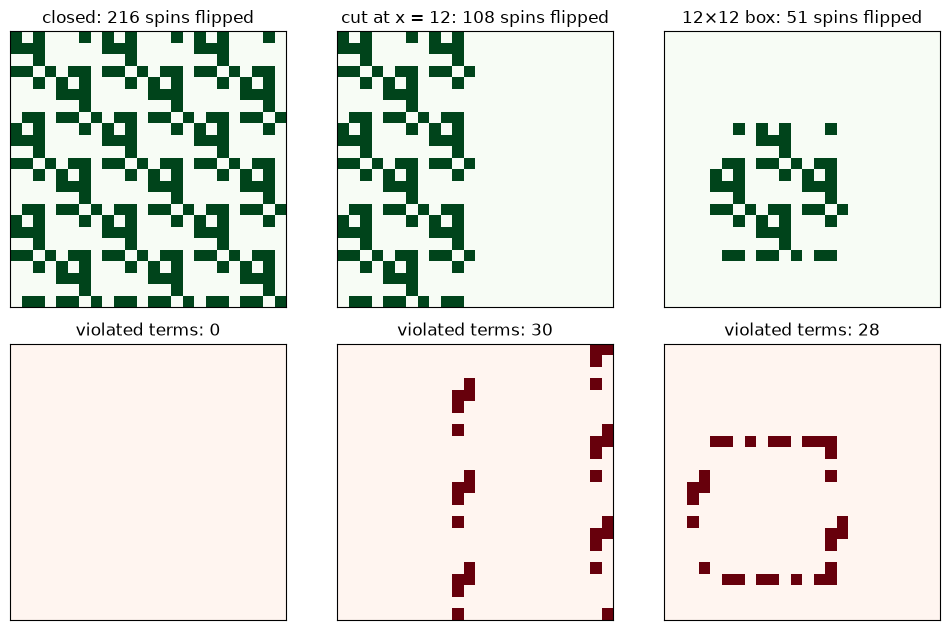

In [12]:
L = 24
F = TRI.check_matrix(L)[:, L * L:]
S = TRI.symmetries(L)
u = S[int(np.argmax(S.sum(1)))].reshape(L, L)
half = np.zeros((L, L), bool); half[: L // 2] = True
box = np.zeros((L, L), bool); box[4:16, 4:16] = True
fig, axes = plt.subplots(2, 3, figsize=(10, 6.4))
for j, (region, title) in enumerate([(np.ones((L, L), bool), "closed"), (half, "cut at x = 12"), (box, "12×12 box")]):
    patch, viol = fractals.truncate(u, F, region)
    axes[0, j].imshow(patch.T, cmap=GREENS, origin="lower")
    axes[0, j].set_title(f"{title}: {int(patch.sum())} spins flipped")
    axes[1, j].imshow(viol.reshape(L, L).T, cmap="Reds", origin="lower", vmin=0, vmax=1)
    axes[1, j].set_title(f"violated terms: {int(viol.sum())}")
    for i in (0, 1):
        axes[i, j].set_xticks([]), axes[i, j].set_yticks([])
plt.tight_layout()

## 7. Restricted mobility

Flipping $u$ changes the syndrome by $Fu$, so "can an operator move a defect?" is "is this syndrome in
the column space of $F$?". Two different questions:

1. **Locally:** is there *any* operator inside a $w\times w$ box (every weight, every shape) that
   produces two defects a distance $d$ apart? An exact linear solve.
2. **Globally:** $s\in\operatorname{im}F\iff v^{\mathsf T}s=0$ for every relation $v\in\ker F^{\mathsf T}$. Each
   relation is a conserved, fractal-shaped parity that every excitation pattern must satisfy.

In [13]:
def solve(A, s):
    """A x = s over GF(2); a solution or None."""
    R, piv = gsd.rref(np.concatenate([A, s.reshape(-1, 1)], axis=1))
    if A.shape[1] in piv:
        return None
    x = np.zeros(A.shape[1], dtype=np.int64)
    x[piv] = R[: len(piv), -1]
    return x


def syndrome(L, sites):
    s = np.zeros((L, L), dtype=np.int64)
    for i, j in sites:
        s[i % L, j % L] ^= 1
    return s.reshape(-1)


L = 20
F = TRI.check_matrix(L)[:, L * L:]
one = np.zeros((L, L), dtype=np.int64); one[10, 10] = 1
print("one spin flip at (10, 10) violates", [tuple(map(int, p)) for p in np.argwhere((F @ one.reshape(-1) % 2).reshape(L, L))],
      " (the reflected stencil)")

def local(model, L, sites, w, centre=(10, 10)):
    F = model.check_matrix(L)[:, L * L:]
    cols = [((centre[0] - w // 2 + i) % L) * L + (centre[1] - w // 2 + j) % L for i in range(w) for j in range(w)]
    return solve(F[:, cols], syndrome(L, sites)) is not None

print("\n(1) any operator inside a box of side 7, 11 or 15 that creates a defect pair at distance d?")
for name, step in [("along x", (1, 0)), ("along y", (0, 1)), ("diagonal", (1, 1))]:
    print(f"   trinomial {name:9s}", ["yes" if any(local(TRI, L, [(10, 10), (10 + d * step[0], 10 + d * step[1])], w)
                                          for w in (7, 11, 15)) else "no" for d in range(1, 6)])
print("   control f = 1 + x, along x", ["yes" if local(DW, L, [(10, 10), (10 + d, 10)], 11) else "no" for d in range(1, 6)])

print("\n(2) any operator on the whole torus?")
for LL in (16, 20, 24):
    F = TRI.check_matrix(LL)[:, LL * LL:]
    out = []
    for d in range(1, 5):
        x = solve(F, syndrome(LL, [(10, 10), (10 + d, 10)]))
        out.append("no" if x is None else f"weight {int(x.sum())}/{LL * LL}")
    print(f"   L={LL}: N_c={TRI.log_gsd(LL):2d}  d=1..4:", out)

one spin flip at (10, 10) violates [(8, 10), (9, 10), (10, 9), (10, 10)]  (the reflected stencil)

(1) any operator inside a box of side 7, 11 or 15 that creates a defect pair at distance d?


   trinomial along x   ['no', 'no', 'no', 'no', 'no']
   trinomial along y   ['no', 'no', 'no', 'no', 'no']


   trinomial diagonal  ['no', 'no', 'no', 'no', 'no']


   control f = 1 + x, along x ['yes', 'yes', 'yes', 'yes', 'yes']

(2) any operator on the whole torus?
   L=16: N_c=16  d=1..4: ['no', 'no', 'no', 'no']
   L=20: N_c= 4  d=1..4: ['no', 'no', 'no', 'weight 136/400']
   L=24: N_c= 8  d=1..4: ['no', 'no', 'no', 'no']


No local operator of any shape moves a single defect, while for the control $f=1+x$ a string does it at
every distance. Globally, some separated pairs can be created, but only by operators of weight
$\sim N/2$ — torus-wrapping membranes, not transport — and which tori allow it is decided by the same
arithmetic that sets $N_c$. That is restricted mobility in its sharp form.

**Open threads.** Add the cross term ($f=1+x+x^2+y+xy$) to force a singular point like `haah_z`'s;
classify mobility under fractal-shaped rather than box-shaped regions; and compare with Haah's 3D cubic
code, where point-like fractons appear natively — notebook 05.